# Saudi Stock Market (Tadawul) 2022 – 2025 — Exploratory Data Analysis
**Author:** Tarfah Alsunaidi

## Problem Definition

### The dataset
**Source:** [Saudi Arabian Stock Market Data – Kaggle](https://www.kaggle.com/datasets/abdelrahmanalimo/saudi-arabian-stock-market-data)

The dataset records the daily trading history of the Saudi Stock Exchange (Tadawul) from  2 January 2022 to 14 December 2025.
It has 158,160 rows and 11 columns, covering 172 listed stocks. Each row is one stock on one trading day:

| Column | Meaning |
|---|---|
| `Date` | Trading day (stored as text with the +03:00 Riyadh offset) |
| `Open`, `High`, `Low`, `Close` | Daily prices in SAR |
| `Volume` | Number of shares traded |
| `Dividends`, `Stock Splits` | Corporate actions on that day |
| `Symbol`, `Name`, `Yahoo_Symbol` | Tadawul code, company name, Yahoo Finance ticker |

### Why I selected it
The Saudi market is one of the largest in the region and is changing fast under Vision 2030.
The dataset is large, real and covers every sector over four years. It is also realistic as it contains missing values, placeholder rows and labelling errors that have to be found and fixed before any analysis can be trusted.

### Goal
Analyse the Saudi stock market from 2022 to 2025 to understand how the major sectors performed, whether unusual trading-volume spikes come with big price moves, how strongly the largest stocks move together, and which stocks are the most volatile relative to their price.

### Analysis questions
1. How have the major Saudi sectors performed overall across 2022 – 2025?
2. Do massive spikes in daily trading volume reliably coincide with major price breakouts or higher volatility?
3. How strongly are the top (blue-chip) stocks correlated with each other?
4. Which stocks show the highest price volatility relative to their average price?

### What insights do you expect to uncover?

- **Sector performance:** I expect sectors to perform very differently over 2022 – 2025.
- **Volume spikes:** I expect days with unusually high trading volume to come with larger price moves and more frequent breakouts, but not always in the same direction.
- **Blue-chip correlation:** I expect the largest stocks to move together positively, with stronger links between companies in the same sector. I also expect them to move together more during stressful market periods.
- **Volatility:** I expect smaller and less-traded stocks to be more volatile relative to their price than large, stable companies, and the most volatile stocks to cluster in a few sectors.
- **Data quality:** As a real market dataset, I expect to find issues that need to be cleaned before the analysis can be trusted.

## 1. Data Loading and Structure

In [99]:
# Import libraries
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid")
GREEN, RED, EMERALD, SAND, INK = "#2E8B57", "#C4553E", "#2F6F62", "#C2A267", "#24303A"
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 13})
R = {}   # Results, quoted in the written insights

In [100]:
# Load the dataset
DATA_DIR = "data"
df = pd.read_csv(f"{DATA_DIR}/ALL_SAUDI_STOCKS_2022_TO_TODAY.csv")
df.head()

,Date,Open,High,Low,Close,Volume,Dividends,Stock Splits,Symbol,Name,Yahoo_Symbol
0,2022-01-02 00:00:00+03:00,22.544126,22.668909,22.294559,22.294559,1439168,0.0,0.0,1010,Riyad Bank,1010.SR
1,2022-01-03 00:00:00+03:00,22.377747,22.793690,22.377747,22.668907,3540055,0.0,0.0,1010,Riyad Bank,1010.SR
2,2022-01-04 00:00:00+03:00,22.793690,22.793690,22.544125,22.668907,1880393,0.0,0.0,1010,Riyad Bank,1010.SR
3,2022-01-05 00:00:00+03:00,22.710503,23.084852,22.668909,22.960070,2433931,0.0,0.0,1010,Riyad Bank,1010.SR
4,2022-01-06 00:00:00+03:00,23.001661,23.292822,22.835285,23.084850,1938160,0.0,0.0,1010,Riyad Bank,1010.SR


In [101]:
# Shape of the dataset
print(df.shape)
print("Rows:", df.shape[0], "| Columns:", df.shape[1])
print("Stocks:", df["Symbol"].nunique(), "| From", df["Date"].min()[:10], "to", df["Date"].max()[:10])

(158160, 11)
Rows: 158160 | Columns: 11
Stocks: 172 | From 2022-01-02 to 2025-12-14


In [102]:
# Data types
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 158160 entries, 0 to 158159
Data columns (total 11 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   Date          158160 non-null  object 
 1   Open          158159 non-null  float64
 2   High          158159 non-null  float64
 3   Low           158159 non-null  float64
 4   Close         158159 non-null  float64
 5   Volume        158160 non-null  int64  
 6   Dividends     158160 non-null  float64
 7   Stock Splits  158160 non-null  float64
 8   Symbol        158160 non-null  int64  
 9   Name          158160 non-null  object 
 10  Yahoo_Symbol  158160 non-null  object 
dtypes: float64(6), int64(2), object(3)
memory usage: 13.3+ MB


In [103]:
# Summary statistics
df.describe().round(2)

,Open,High,Low,Close,Volume,Dividends,Stock Splits,Symbol
count,158159.00,158159.00,158159.00,158159.00,1.581600e+05,158160.00,158160.00,158160.00
mean,46.82,47.41,46.23,46.79,1.016324e+06,0.00,0.00,4036.23
std,77.24,78.32,76.23,77.22,3.792294e+06,0.09,0.39,2151.26
min,0.79,0.79,0.78,0.78,0.000000e+00,0.00,0.00,1010.00
25%,13.68,13.83,13.52,13.66,8.543775e+04,0.00,0.00,2270.00
50%,24.85,25.15,24.56,24.82,2.608780e+05,0.00,0.00,4021.00
75%,47.51,48.09,46.95,47.47,8.385128e+05,0.00,0.00,4320.00
max,1274.65,1277.62,1224.10,1248.88,6.562831e+08,10.00,100.00,8300.00


In [104]:
# Missing values (count and percentage)
pd.DataFrame({"missing": df.isnull().sum(), "percent": (df.isnull().mean() * 100).round(4)})

,missing,percent
Date,0,0.0000
Open,1,0.0006
High,1,0.0006
Low,1,0.0006
Close,1,0.0006
Volume,0,0.0000
Dividends,0,0.0000
Stock Splits,0,0.0000
Symbol,0,0.0000
Name,0,0.0000


## 2. Data Cleaning

### 2.1 Missing values
Only one row has missing prices (0.0006 % of the data), so it is dropped. `.copy()` creates an independent DataFrame .

In [105]:
df_clean = df.dropna().copy()
print("Original shape:", df.shape)
print("After dropping missing values:", df_clean.shape)

Original shape: (158160, 11)
After dropping missing values: (158159, 11)


### 2.2 Duplicates
Two checks: identical rows, and the same stock appearing twice on the same day (which would double-count trading).

In [106]:
print("Identical rows:", df_clean.duplicated().sum())
print("Same stock & same day:", df_clean.duplicated(subset=["Symbol", "Date"]).sum())

Identical rows: 0
Same stock & same day: 0


No duplicates of either kind were found.

### 2.3 Dates and calendar features
Dates are stored as text with the Riyadh offset (`+03:00`). They are converted to plain Riyadh trading dates, then calendar
columns are added for time-based grouping.

In [107]:
df_clean["Date"] = (pd.to_datetime(df_clean["Date"], utc=True)
                    .dt.tz_convert("Asia/Riyadh").dt.tz_localize(None).dt.normalize())
df_clean["Quarter"] = df_clean["Date"].dt.quarter
df_clean["Year_Month"] = df_clean["Date"].dt.strftime("%Y-%m")
df_clean["Year"] = df_clean["Date"].dt.year
df_clean["Month"] = df_clean["Date"].dt.month
df_clean["Day"] = df_clean["Date"].dt.day
df_clean["Day_Name"] = df_clean["Date"].dt.day_name()
df_clean.head()

,Date,Open,High,Low,Close,Volume,Dividends,Stock Splits,Symbol,Name,Yahoo_Symbol,Quarter,Year_Month,Year,Month,Day,Day_Name
0,2022-01-02,22.544126,22.668909,22.294559,22.294559,1439168,0.0,0.0,1010,Riyad Bank,1010.SR,1,2022-01,2022,1,2,Sunday
1,2022-01-03,22.377747,22.793690,22.377747,22.668907,3540055,0.0,0.0,1010,Riyad Bank,1010.SR,1,2022-01,2022,1,3,Monday
2,2022-01-04,22.793690,22.793690,22.544125,22.668907,1880393,0.0,0.0,1010,Riyad Bank,1010.SR,1,2022-01,2022,1,4,Tuesday
3,2022-01-05,22.710503,23.084852,22.668909,22.960070,2433931,0.0,0.0,1010,Riyad Bank,1010.SR,1,2022-01,2022,1,5,Wednesday
4,2022-01-06,23.001661,23.292822,22.835285,23.084850,1938160,0.0,0.0,1010,Riyad Bank,1010.SR,1,2022-01,2022,1,6,Thursday


### 2.4 Rows with zero trading volume
7,837 rows have `Volume = 0`. I tried to fill them from Yahoo Finance, but Yahoo is the same source as the dataset and returns 0 for these days as well, so nothing actually changed.

In [108]:
zero = df_clean["Volume"] == 0
flat = df_clean["High"] == df_clean["Low"]
print("Rows with zero volume:", zero.sum())
print("…of which the price did not move at all (High = Low):", (zero & flat).sum())

stocks_per_day = df_clean.groupby("Date")["Symbol"].nunique()
zero_per_day = df_clean[zero].groupby("Date")["Symbol"].nunique()
share = (zero_per_day / stocks_per_day.reindex(zero_per_day.index)).sort_values(ascending=False)
print("\nDays where at least 90 % of all stocks show zero volume:", (share >= 0.9).sum())
share.head(10).rename("share of stocks with zero volume").to_frame().style.format("{:.0%}")

Rows with zero volume: 7837
…of which the price did not move at all (High = Low): 7837

Days where at least 90 % of all stocks show zero volume: 34


,share of stocks with zero volume
Date,
2022-01-27 00:00:00,99%
2023-03-27 00:00:00,99%
2023-03-28 00:00:00,99%
2023-03-26 00:00:00,99%
2022-10-31 00:00:00,99%
2023-01-15 00:00:00,98%
2023-03-19 00:00:00,98%
2023-01-22 00:00:00,98%
2023-02-12 00:00:00,98%


In [109]:
R["zero_rows"] = f"{int(zero.sum()):,}"
R["zero_flat"] = f"{int((zero & flat).sum()):,}"
R["zero_days90"] = int((share >= 0.9).sum())

Every one of the 7,837 zero-volume rows also has a completely flat price, and on 34 days almost the whole market shows zero volume at once. These are placeholder rows for non-trading days, not real sessions with no buyers. Filling them would invent trades, and keeping them would add fake 0 % returns, so they are dropped.

In [110]:
df_clean = df_clean[~(zero & flat)].copy()
print("Rows after removing placeholder days:", f"{len(df_clean):,}")

Rows after removing placeholder days: 150,322


### 2.5 Company names
The company names (sectors) were attached from Yahoo Finance while preparing the data. Before using them, they are
checked:
* The same name is attached to several different symbols
* Some prices do not match the name (symbol 7203 trades around 800 SAR, which is Elm, but it is labelled Salama Coop).

In [111]:
shared = df_clean.groupby("Name")["Symbol"].unique()
shared = shared[shared.map(len) > 1].map(lambda s: ", ".join(map(str, sorted(s))))
print("Names used by more than one symbol:", len(shared))
shared.rename("symbols").to_frame()

Names used by more than one symbol: 10


,symbols
Name,
Alandalus,"1304, 4191"
Alinma Bank,"1150, 4061"
Almarai,"2280, 4030"
Jabal Omar,"4190, 4330"
Jarir,"2090, 4001"
Mouwasat,"4002, 4170"
SABIC,"2010, 2020, 2030"
Seera,"2190, 4220"
Sipchem,"2250, 2310"


The symbol (Tadawul code) is the reliable key, because the prices were downloaded by symbol. The names are corrected using the
official list of Tadawul-listed companies (`tadawul_companies.csv`, which also gives each company's official industry group).

In [112]:
companies = pd.read_csv(f"{DATA_DIR}/tadawul_companies.csv")
name_map = dict(zip(companies["Symbol"], companies["Company_Name"]))
group_map = dict(zip(companies["Symbol"], companies["Industry_Group"]))

old = df_clean.drop_duplicates("Symbol").set_index("Symbol")["Name"]
new = old.index.map(lambda s: name_map.get(s, old[s]))
changed = pd.DataFrame({"name in dataset": old.values, "official name": new}, index=old.index)
changed = changed[changed["name in dataset"].str.lower() != changed["official name"].str.lower()]
print("Symbols whose name was corrected:", len(changed))
R["names_fixed"] = len(changed)
changed.head(12)

Symbols whose name was corrected: 111


,name in dataset,official name
Symbol,,
1050,BSF,Banque Saudi Fransi
1060,SABB,SAB
1080,Arab National Bank,ANB
2001,Chem,Chemanol
2020,SABIC,SABIC Agri-Nutrients
2030,SABIC,SARCO
2050,Safco,Savola Group
2060,Petrochem,Tasnee
2090,Jarir,NGC


In [113]:
df_clean["Name"] = df_clean["Symbol"].map(lambda s: name_map.get(s)).fillna(df_clean["Name"])
print("Symbols still sharing a name:", (df_clean.groupby("Name")["Symbol"].nunique() > 1).sum())

Symbols still sharing a name: 0


### 2.6 Sectors
The dataset took sectors from Yahoo Finance. Yahoo's classification puts insurance companies inside Financial Services
and has no sector for the delisted symbol 8270. Tadawul's own industry groups are more accurate and match what investors
see on the exchange, so they are used instead.

In [114]:
df_clean["Sector"] = df_clean["Symbol"].map(group_map)
print("Stocks without a group:", df_clean.loc[df_clean["Sector"].isna(), "Symbol"].nunique())
df_clean.drop_duplicates("Symbol")["Sector"].value_counts().rename("companies").to_frame()

Stocks without a group: 0


,companies
Sector,
Materials,34
Insurance,23
Real Estate Mgmt & Dev't,15
Health Care Equipment & Svcs,12
Food & Beverages,12
Banks,10
Capital Goods,8
Consumer Discretionary Distribution & Retail,8
Consumer Staples Distribution & Retail,7


### 2.7 Impossible daily moves
Tadawul limits a stock's daily move to **±10 %**. Daily returns larger than that cannot be real trading; they come from
split / adjustment glitches in the source (the price jumps on the adjustment date).

In [115]:
df_clean = df_clean.sort_values(["Symbol", "Date"]).reset_index(drop=True)
df_clean["Daily_Return"] = df_clean.groupby("Symbol")["Close"].pct_change()
invalid = df_clean["Daily_Return"].abs() > 0.105
print("Returns beyond the ±10 % limit:", invalid.sum())
R["invalid"] = int(invalid.sum())
(df_clean.loc[invalid, ["Date", "Symbol", "Name", "Close", "Volume", "Daily_Return"]]
 .assign(Daily_Return=lambda d: d["Daily_Return"].map("{:+.1%}".format))
 .sort_values("Date").head(10))

Returns beyond the ±10 % limit: 101


,Date,Symbol,Name,Close,Volume,Daily_Return
124151,2022-01-23,7040,Atheeb Telecom,10.267094,17158804,-58.0%
124152,2022-01-30,7040,Atheeb Telecom,22.678200,2861543,+120.9%
88446,2022-01-30,4140,SIECO,4.530773,23988548,+10.9%
97174,2022-01-30,4180,Fitaihi Group,4.744535,20665020,+14.1%
78171,2022-01-30,4050,SASCO,36.460098,10382346,+27.9%
77231,2022-01-30,4040,SAPTCO,24.500000,3811893,+11.5%
127896,2022-02-17,7203,Elm,188.764832,12348923,+18.8%
23538,2022-04-05,2082,ACWA Power,171.914185,2383803,+21.0%
127927,2022-04-05,7203,Elm,228.695877,2935840,+12.9%
5674,2022-04-05,1111,Tadawul Group,204.353622,1864082,+14.3%


These 101 returns are set to missing (the prices themselves are kept), so they cannot distort the return, correlation and volatility analysis.

In [116]:
df_clean.loc[invalid, "Daily_Return"] = np.nan

### 2.8 Feature engineering, renaming and saving

In [117]:
# New features
df_clean["Traded_Value"] = df_clean["Close"] * df_clean["Volume"]                 # SAR traded that day
df_clean["Intraday_Range"] = (df_clean["High"] - df_clean["Low"]) / df_clean["Close"]   # how far the price swung

# Clear column names
df_clean = df_clean.rename(columns={
    "Open": "Open_Price", "High": "High_Price", "Low": "Low_Price", "Close": "Close_Price",
    "Volume": "Trade_Volume", "Stock Splits": "Stock_Splits", "Symbol": "Stock_Symbol",
    "Name": "Company_Name", "Yahoo_Symbol": "Yahoo_Stock_Symbol", "Sector": "Stock_Sector"})

base_cols = ["Date", "Open_Price", "High_Price", "Low_Price", "Close_Price", "Trade_Volume", "Dividends",
             "Stock_Splits", "Stock_Symbol", "Company_Name", "Yahoo_Stock_Symbol", "Quarter", "Year_Month",
             "Year", "Month", "Day", "Day_Name", "Stock_Sector"]
df_clean[base_cols].to_csv(f"{DATA_DIR}/Saudi_Tadawul_Cleaned_Dataset.csv", index=False)
print("Saved:", df_clean[base_cols].shape)

Saved: (150322, 18)


In [118]:
summary = pd.DataFrame({
    "step": ["Raw data", "Drop missing prices", "Drop non-trading placeholder rows", "Final clean data"],
    "rows": [len(df), len(df) - 1, len(df_clean), len(df_clean)]})
summary["rows"] = summary["rows"].map("{:,}".format)
summary

,step,rows
0,Raw data,"158,160"
1,Drop missing prices,"158,159"
2,Drop non-trading placeholder rows,"150,322"
3,Final clean data,"150,322"


1 row with missing prices and 7,837 placeholder rows removed; 111 company names
corrected; sectors replaced by Tadawul's official industry groups; 101 impossible daily returns neutralised;
two new features added (`Traded_Value`, `Intraday_Range`) and `Daily_Return` for the analysis.

## 3. Exploratory Data Analysis — Univariate
Each chart below looks at one variable at a time.

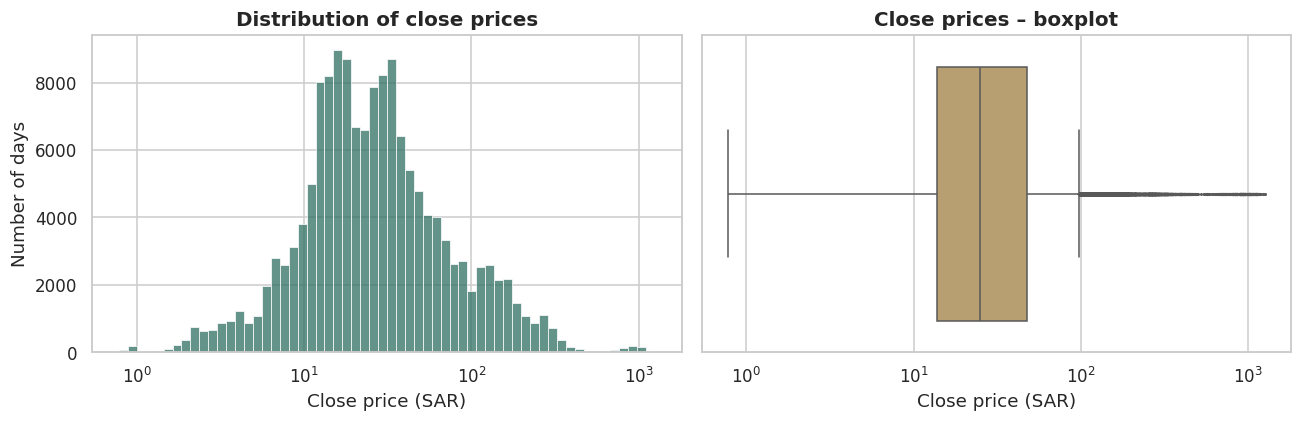


Median 24.80 SAR | mean 46.94 SAR | max 1,248.88 SAR | skewness 6.8


In [120]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df_clean["Close_Price"], bins=60, log_scale=True, color=EMERALD, ax=ax[0])
ax[0].set(title="Distribution of close prices", xlabel="Close price (SAR)", ylabel="Number of days")
sns.boxplot(x=df_clean["Close_Price"], color=SAND, ax=ax[1], fliersize=1)
ax[1].set(title="Close prices – boxplot", xlabel="Close price (SAR)", xscale="log")
plt.tight_layout(); plt.show()
p = df_clean["Close_Price"]
R["price_median"], R["price_mean"], R["price_max"] = f"{p.median():.1f}", f"{p.mean():.1f}", f"{p.max():,.0f}"
print(f"\nMedian {p.median():.2f} SAR | mean {p.mean():.2f} SAR | max {p.max():,.2f} SAR | skewness {p.skew():.1f}")

**Insight:** Prices are strongly right-skewed (skewness = 6.8). Half of all daily closes are below 24.8 SAR, while a small number of high-priced stocks (up to 1,249 SAR) pull the mean up to 46.9 SAR, almost twice the median. Because of this, a log scale is needed to see the shape of the distribution. The points beyond the boxplot’s upper whisker (above roughly 100 SAR) are real expensive stocks, not errors, so they are kept. For comparing stocks, the median is a better summary than the mean.

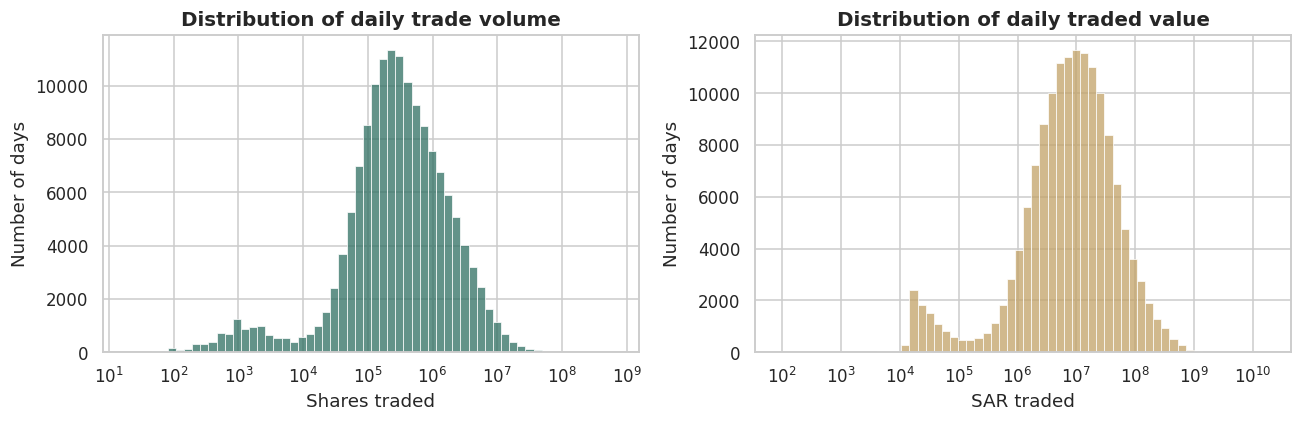


Median traded value per stock per day: 8.4 M SAR | mean 27.4 M SAR


In [121]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df_clean["Trade_Volume"], bins=60, log_scale=True, color=EMERALD, ax=ax[0])
ax[0].set(title="Distribution of daily trade volume", xlabel="Shares traded", ylabel="Number of days")
sns.histplot(df_clean["Traded_Value"], bins=60, log_scale=True, color=SAND, ax=ax[1])
ax[1].set(title="Distribution of daily traded value", xlabel="SAR traded", ylabel="Number of days")
plt.tight_layout(); plt.show()
v = df_clean["Traded_Value"]
R["value_median"] = f"{v.median() / 1e6:.1f}"
print(f"\nMedian traded value per stock per day: {v.median() / 1e6:.1f} M SAR | mean {v.mean() / 1e6:.1f} M SAR")

**Insight:** on the log scale, volume and traded value look roughly bell-shaped, so trading activity is spread over several
orders of magnitude. A typical stock trades about 8.4 M SAR a day, but a handful of giants trade far more,
which is why liquidity analysis must use medians or log scales.

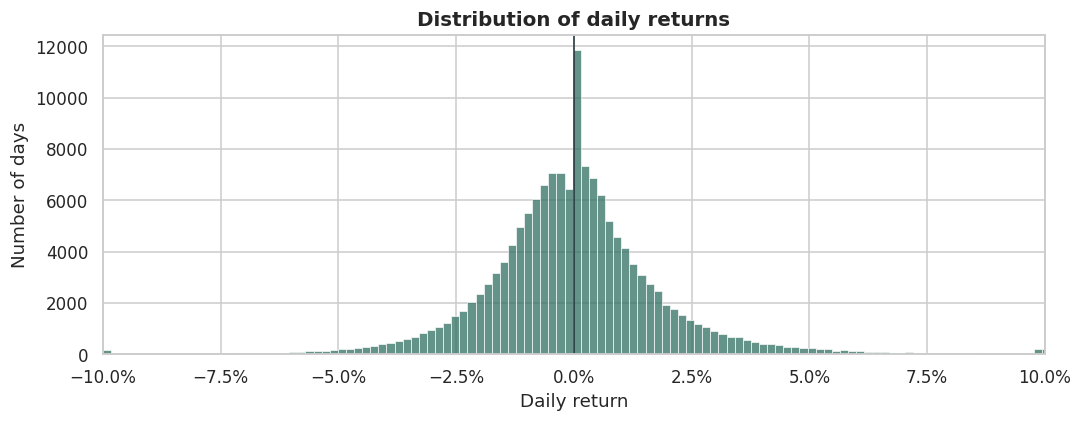


Mean -0.010% | std 1.97% | share of days within ±2 %: 79% | kurtosis 4.6


In [122]:
r = df_clean["Daily_Return"].dropna()
fig, ax = plt.subplots(figsize=(10, 4))
sns.histplot(r, bins=120, color=EMERALD, ax=ax)
ax.axvline(0, color=INK, lw=1)
ax.set(title="Distribution of daily returns", xlabel="Daily return", ylabel="Number of days", xlim=(-0.1, 0.1))
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0))
plt.tight_layout(); plt.show()
R["ret_std"] = f"{r.std():.2%}"
R["ret_within2"] = f"{(r.abs() <= 0.02).mean():.0%}"
print(f"\nMean {r.mean():+.3%} | std {r.std():.2%} | share of days within ±2 %: {(r.abs() <= 0.02).mean():.0%} | kurtosis {r.kurt():.1f}")

**Insight:** daily returns are centred almost exactly on zero with a standard deviation of 1.97%. About
79% of all days move less than ±2 %, but the tails are fat (high kurtosis): big moves happen more often than a
normal distribution would suggest, which matters for risk (question 4).

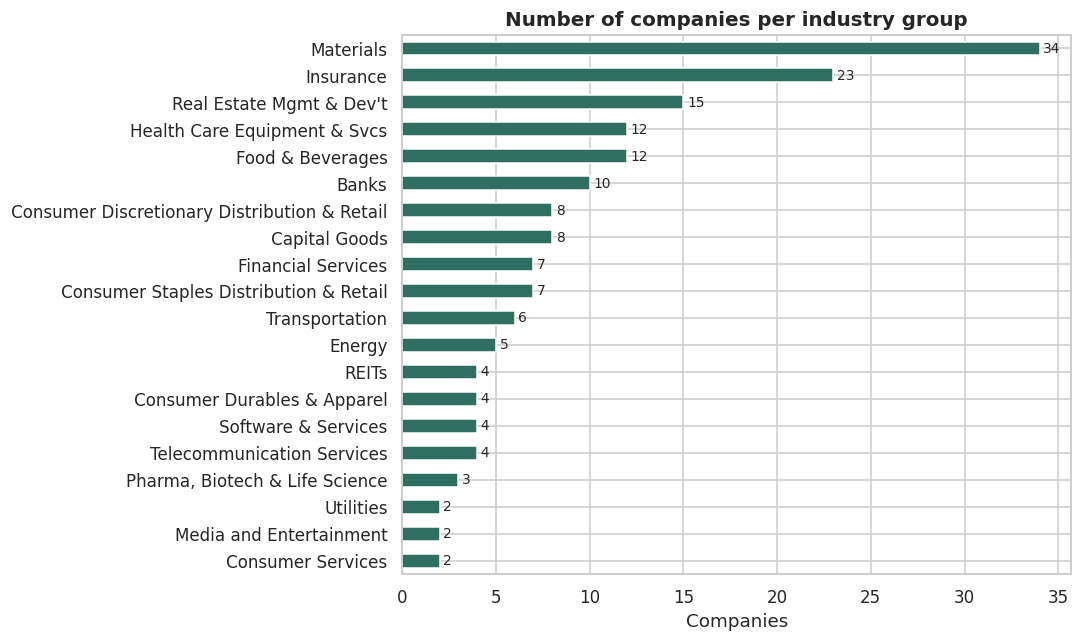

In [123]:
companies_per_group = df_clean.drop_duplicates("Stock_Symbol")["Stock_Sector"].value_counts().sort_values()
fig, ax = plt.subplots(figsize=(10, 6))
companies_per_group.plot.barh(color=EMERALD, ax=ax)
for i, v in enumerate(companies_per_group.values):
    ax.text(v + 0.2, i, str(v), va="center", fontsize=9)
ax.set(title="Number of companies per industry group", xlabel="Companies", ylabel="")
plt.tight_layout(); plt.show()
R["top_group"], R["top_group_n"] = companies_per_group.index[-1], int(companies_per_group.iloc[-1])

**Insight:** the dataset is not balanced across sectors. Materials has the most companies (34), while
several groups have only one or two. Small groups are driven by a single company, so their results must be read with care.

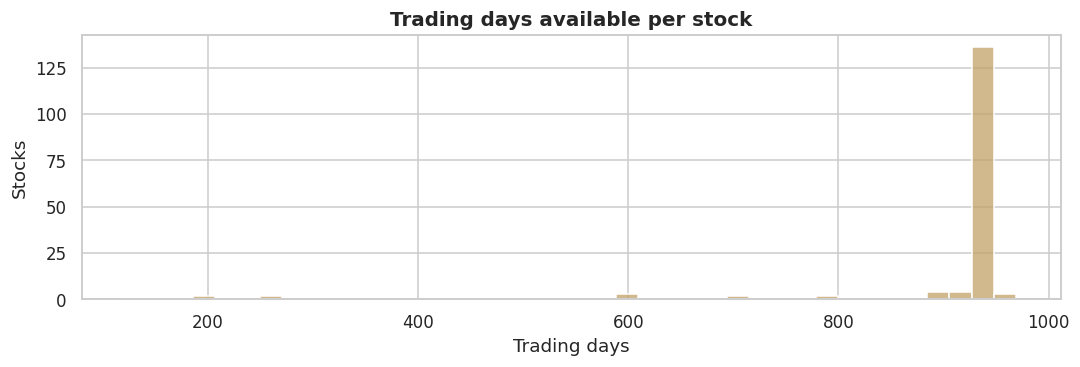


Stocks with (almost) full history: 140 | stocks with < 500 days (newer listings): 13


In [125]:
days = df_clean.groupby("Stock_Symbol")["Date"].nunique()
fig, ax = plt.subplots(figsize=(10, 3.5))
sns.histplot(days, bins=40, color=SAND, ax=ax)
ax.set(title="Trading days available per stock", xlabel="Trading days", ylabel="Stocks")
plt.tight_layout(); plt.show()
R["full_hist"] = int((days >= days.max() * 0.95).sum())
R["short_hist"] = int((days < 500).sum())
print("\nStocks with (almost) full history:", R["full_hist"], "| stocks with < 500 days (newer listings):", R["short_hist"])

**Insight:** 140 stocks cover the whole period, while 13 were listed later (IPOs in 2024 – 2025).
Their shorter history is taken into account by using daily returns and equal weighting instead of raw price levels.

## 4. Exploratory Data Analysis — Bivariate and Multivariate

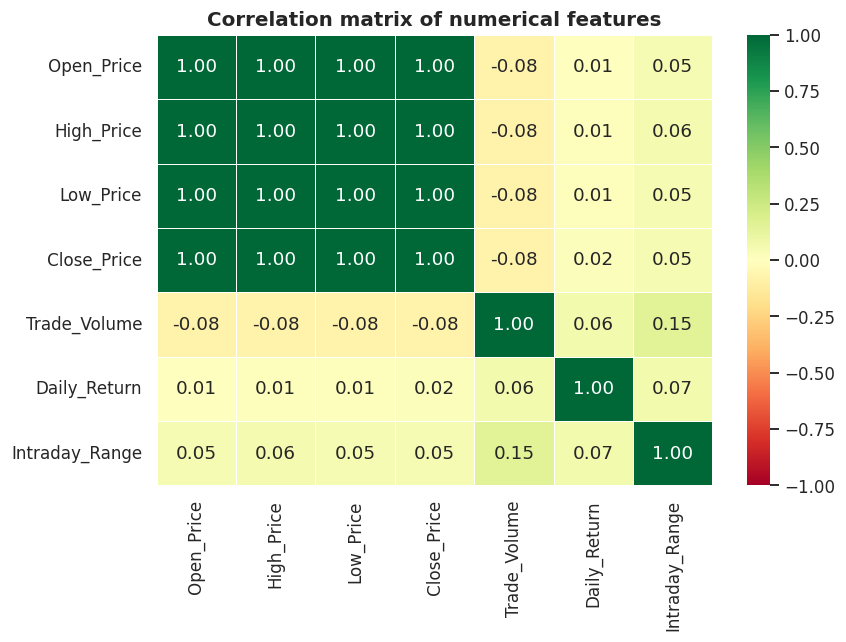

In [126]:
num_cols = ["Open_Price", "High_Price", "Low_Price", "Close_Price", "Trade_Volume", "Daily_Return", "Intraday_Range"]
corr = df_clean[num_cols].corr()
plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdYlGn", vmin=-1, vmax=1, linewidths=.5)
plt.title("Correlation matrix of numerical features"); plt.tight_layout(); plt.show()

**Insight:** Open, High, Low and Close are almost perfectly correlated (≈ 1.00) simply because they are prices of the same
stock on the same day. Intraday_Range
(how much a stock swings in a day) is more related to volume than prices are, and daily returns are nearly independent of the
price level.

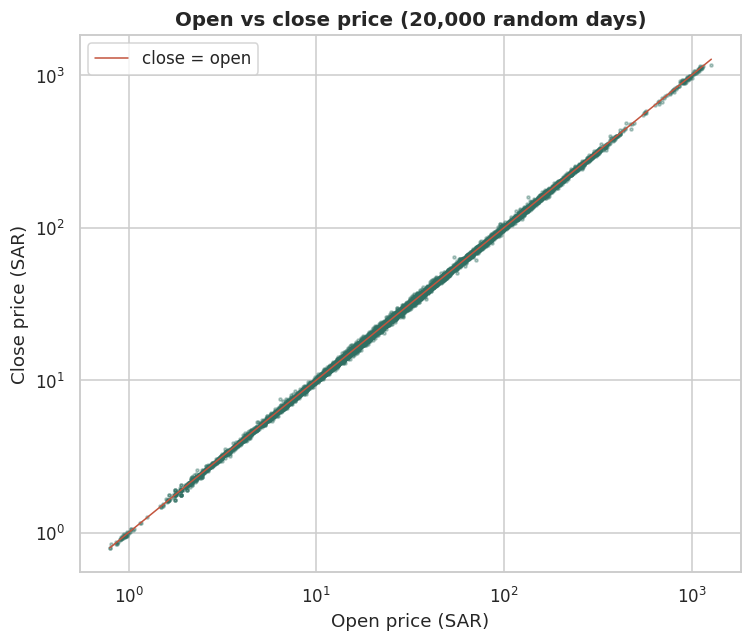

In [127]:
sample = df_clean.sample(20000, random_state=1)
fig, ax = plt.subplots(figsize=(7, 6))
ax.scatter(sample["Open_Price"], sample["Close_Price"], s=4, alpha=.35, color=EMERALD)
ax.set(xscale="log", yscale="log", title="Open vs close price (20,000 random days)", xlabel="Open price (SAR)",
       ylabel="Close price (SAR)")
lims = [sample["Open_Price"].min(), sample["Open_Price"].max()]
ax.plot(lims, lims, color=RED, lw=1, label="close = open")
ax.legend(); plt.tight_layout(); plt.show()

**Insight:** points hug the diagonal: within one day, the close is usually very close to the open. The spread around the line
is the daily move, which is small compared with the huge differences in price between stocks.

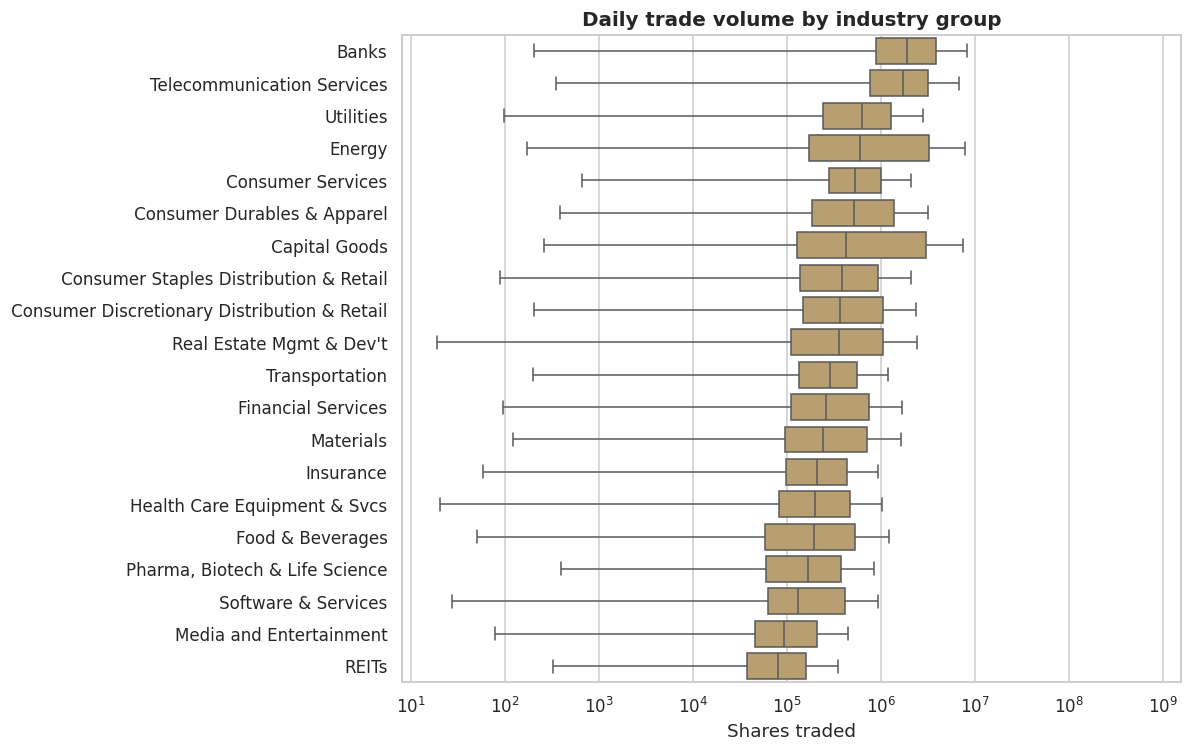

In [128]:
order = df_clean.groupby("Stock_Sector")["Trade_Volume"].median().sort_values(ascending=False).index
plt.figure(figsize=(11, 7))
sns.boxplot(data=df_clean, x="Trade_Volume", y="Stock_Sector", order=order, color=SAND, fliersize=0)
plt.xscale("log"); plt.title("Daily trade volume by industry group"); plt.xlabel("Shares traded"); plt.ylabel("")
plt.tight_layout(); plt.show()

**Insight:** the industry groups differ a lot in how actively their shares trade. Banks (median ~ 1.9 M shares a day) and Telecom (~ 1.7 M) are the most actively traded groups. REITs (~ 80 K) and Media & Entertainment (~ 93 K) trade the fewest shares, so the gap between the most and least traded groups is more than 20×.

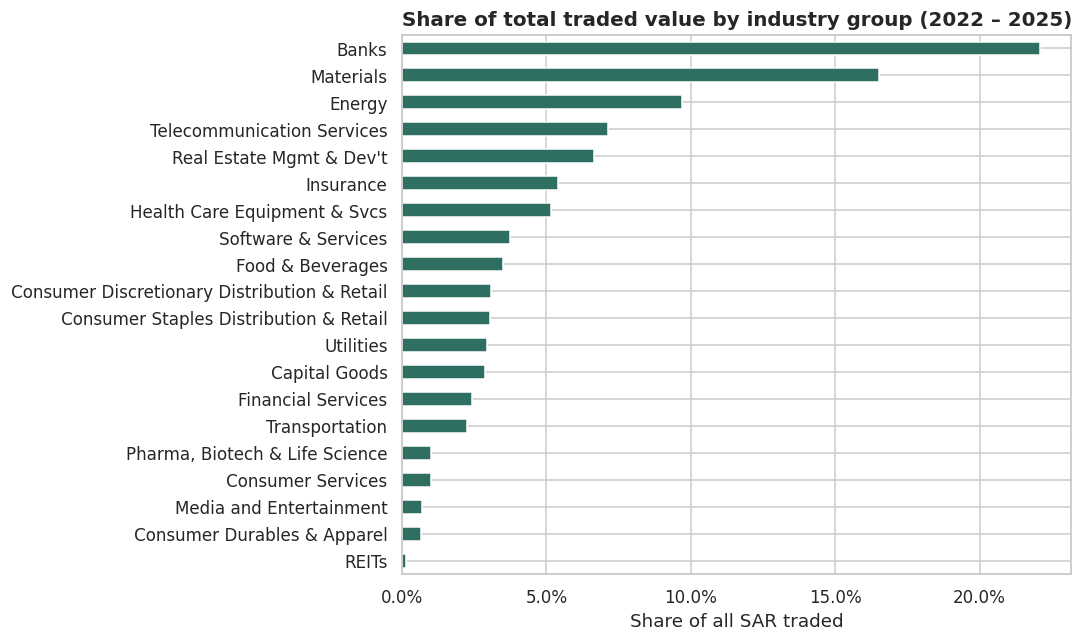

In [86]:
value_by_group = (df_clean.groupby("Stock_Sector")["Traded_Value"].sum() / df_clean["Traded_Value"].sum()).sort_values()
fig, ax = plt.subplots(figsize=(10, 6))
value_by_group.plot.barh(color=EMERALD, ax=ax)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set(title="Share of total traded value by industry group (2022 – 2025)", xlabel="Share of all SAR traded", ylabel="")
plt.tight_layout(); plt.show()
R["liq1"], R["liq1_s"] = value_by_group.index[-1], f"{value_by_group.iloc[-1]:.0%}"
R["liq2"], R["liq2_s"] = value_by_group.index[-2], f"{value_by_group.iloc[-2]:.0%}"

**Insight:** liquidity is concentrated. Banks alone accounts for 22% of all money traded and
Materials for 17%. Sectors with many shares changing hands are not always the ones with the most money traded,
because share prices differ a lot between groups.

## 5. Answering the Analysis Questions

### Q1 · How have the major Saudi sectors performed across 2022 – 2025?
For each industry group, I will take the average daily return of its stocks (equal weight) and compound it into an index
that starts at 100. Equal weighting stops one giant (for example Saudi Aramco) from hiding everything else in its sector.

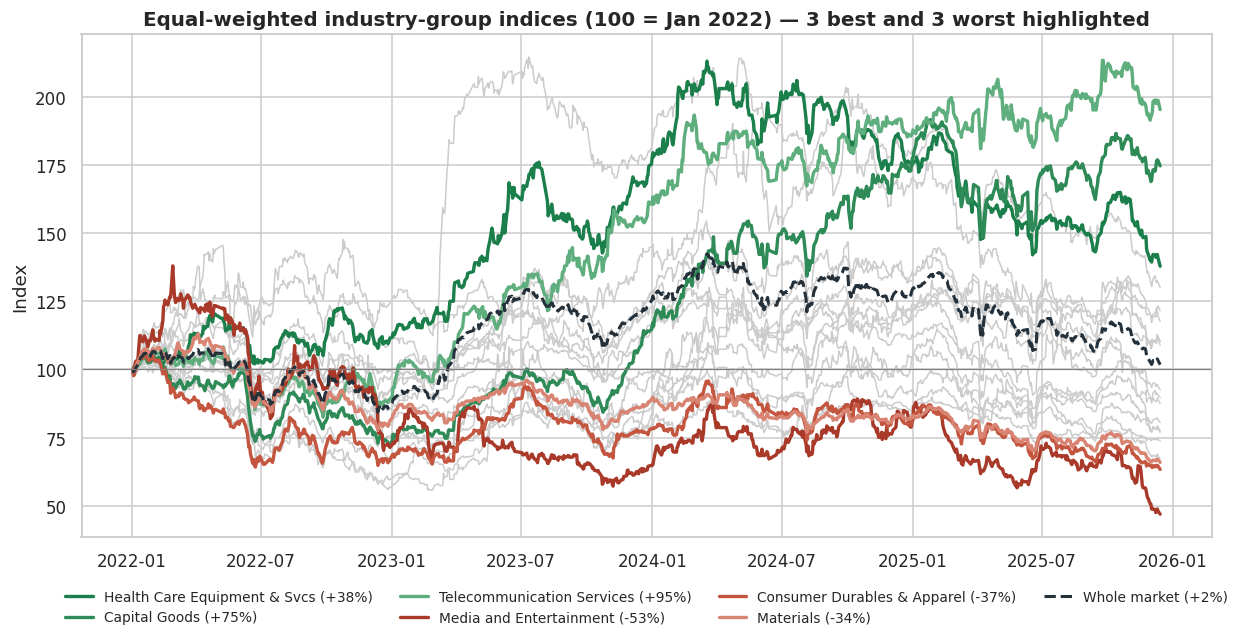

In [87]:
sec_ret = df_clean.groupby(["Date", "Stock_Sector"])["Daily_Return"].mean().unstack().fillna(0)
sec_idx = (1 + sec_ret).cumprod() * 100
total = (sec_idx.iloc[-1] / 100 - 1).sort_values()
market = (1 + df_clean.groupby("Date")["Daily_Return"].mean().fillna(0)).cumprod() * 100

fig, ax = plt.subplots(figsize=(12, 6))
best3, worst3 = total.index[-3:], total.index[:3]
for g in sec_idx.columns:
    if g in best3 or g in worst3:
        continue
    ax.plot(sec_idx.index, sec_idx[g], color="#CCCCCC", lw=1)
for g, c in zip(best3, ["#1B7F4B", "#2E8B57", "#5FAE7E"]):
    ax.plot(sec_idx.index, sec_idx[g], color=c, lw=2.2, label=f"{g} ({total[g]:+.0%})")
for g, c in zip(worst3, ["#A93A2A", "#C4553E", "#D98472"]):
    ax.plot(sec_idx.index, sec_idx[g], color=c, lw=2.2, label=f"{g} ({total[g]:+.0%})")
ax.plot(market.index, market, color=INK, lw=2, ls="--", label=f"Whole market ({market.iloc[-1] / 100 - 1:+.0%})")
ax.axhline(100, color="grey", lw=.8)
ax.set(title="Equal-weighted industry-group indices (100 = Jan 2022) — 3 best and 3 worst highlighted", ylabel="Index")
ax.legend(fontsize=9, ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.08), frameon=False)
plt.tight_layout(); plt.show()

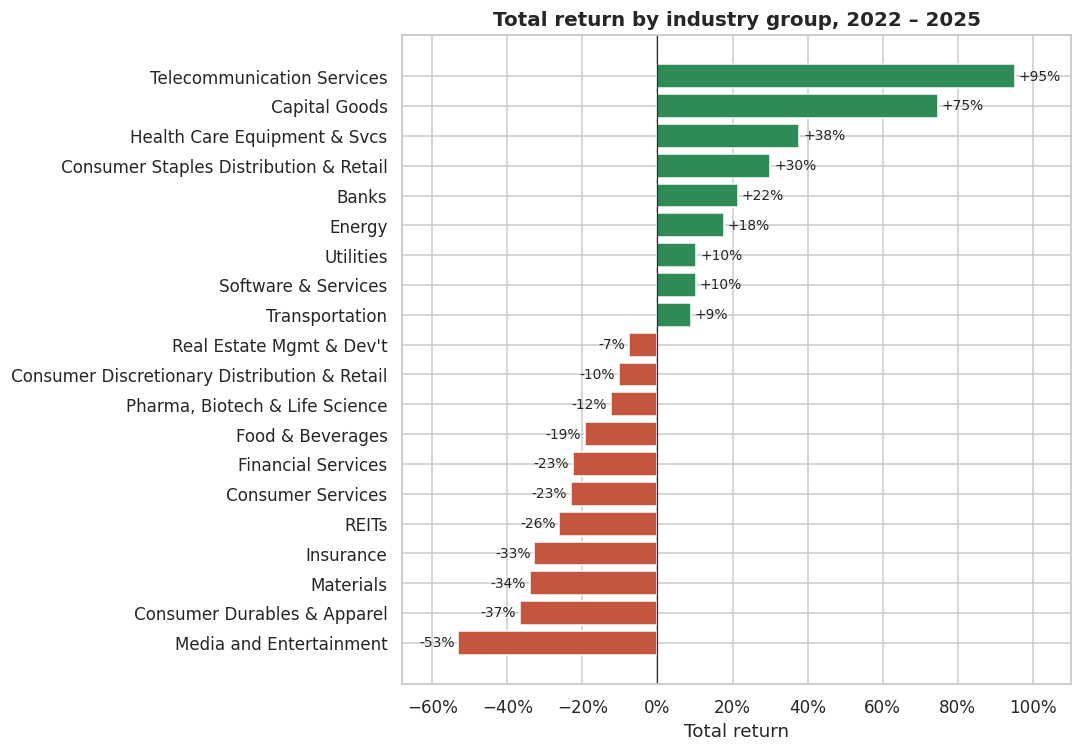

In [88]:
fig, ax = plt.subplots(figsize=(10, 7))
ax.barh(total.index, total.values, color=[GREEN if v >= 0 else RED for v in total.values])
for i, v in enumerate(total.values):
    ax.text(v + (0.01 if v >= 0 else -0.01), i, f"{v:+.0%}", va="center", ha="left" if v >= 0 else "right", fontsize=9)
ax.axvline(0, color=INK, lw=.8)
ax.set_xlim(total.min() - 0.15, total.max() + 0.15)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set(title="Total return by industry group, 2022 – 2025", xlabel="Total return", ylabel="")
plt.tight_layout(); plt.show()
R["q1_best"], R["q1_best_s"] = total.index[-1], f"{total.iloc[-1]:+.0%}"
R["q1_2nd"], R["q1_2nd_s"] = total.index[-2], f"{total.iloc[-2]:+.0%}"
R["q1_worst"], R["q1_worst_s"] = total.index[0], f"{total.iloc[0]:+.0%}"
R["q1_pos"], R["q1_n"] = int((total > 0).sum()), len(total)
R["q1_market"] = f"{market.iloc[-1] / 100 - 1:+.1%}"
R["q1_dd"] = f"{(market / market.cummax() - 1).min():.0%}"

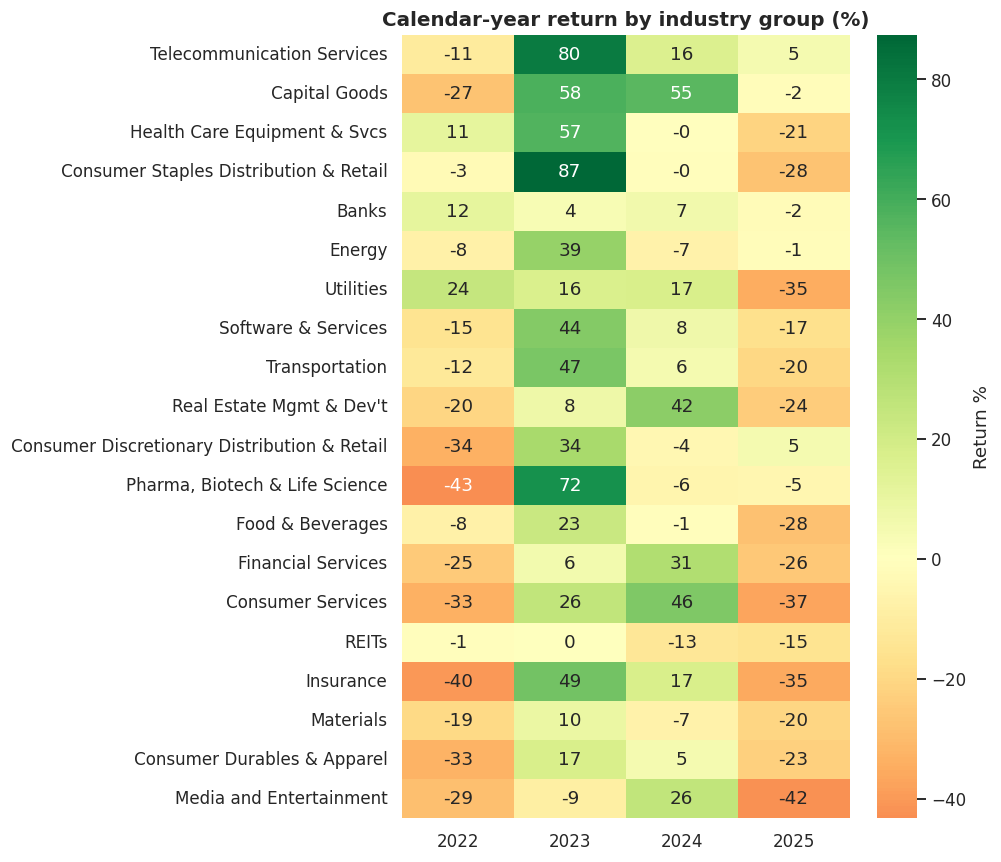

Whole-market return by year: {2022: '-13.2%', 2023: '+42.7%', 2024: '+2.5%', 2025: '-21.7%'}


In [89]:
yearly = sec_ret.groupby(sec_ret.index.year).apply(lambda d: (1 + d).prod() - 1).T
yearly = yearly.loc[total.index[::-1]]
plt.figure(figsize=(9, 8))
sns.heatmap(yearly * 100, annot=True, fmt=".0f", cmap="RdYlGn", center=0, cbar_kws={"label": "Return %"})
plt.title("Calendar-year return by industry group (%)"); plt.xlabel(""); plt.ylabel(""); plt.tight_layout(); plt.show()
mkt_year = market.groupby(market.index.year).last() / market.groupby(market.index.year).first() - 1
R["q1_best_year"], R["q1_worst_year"] = int(mkt_year.idxmax()), int(mkt_year.idxmin())
R["q1_pos_2023"] = int((yearly[2023] > 0).sum())
print("Whole-market return by year:", mkt_year.map("{:+.1%}".format).to_dict())

**Answer Q1:** over the four years the average Saudi stock ended almost flat (+1.7%), with a deepest fall of
-29% along the way, but the industry groups diverged widely. Only 9 of 20 groups finished positive.
Telecommunication Services led (+95%), followed by Capital Goods (+75%), while Media and Entertainment fell the most
(-53%). The yearly heatmap shows the market moved in waves: 2023 was the strongest year
(19 groups rose in 2023), while 2025 was the weakest, with most groups falling. Picking the right
sector mattered far more than being "in the market".

### Q2 · Do massive volume spikes coincide with price breakouts or higher volatility?

* **Volume spike:** a day when a stock trades at least **3 ×** its average volume of the previous 20 sessions (today is not
  part of its own baseline).
* **Breakout:** the close is above the highest price of the previous 20 sessions (a **breakdown** is a close below the lowest).

In [90]:
g = df_clean.groupby("Stock_Symbol")
base = g["Trade_Volume"].transform(lambda s: s.rolling(20, min_periods=10).mean().shift(1))
df_clean["Volume_Ratio"] = df_clean["Trade_Volume"] / base.replace(0, np.nan)
prior_high = g["High_Price"].transform(lambda s: s.rolling(20, min_periods=10).max().shift(1))
prior_low = g["Low_Price"].transform(lambda s: s.rolling(20, min_periods=10).min().shift(1))
df_clean["Breakout_Up"] = df_clean["Close_Price"] > prior_high
df_clean["Breakout_Down"] = df_clean["Close_Price"] < prior_low

v = df_clean.dropna(subset=["Volume_Ratio", "Daily_Return"])
spike, normal = v[v["Volume_Ratio"] >= 3], v[v["Volume_Ratio"] < 3]
comparison = pd.DataFrame({
    "Spike days": [len(spike), spike["Daily_Return"].abs().mean(), spike["Breakout_Up"].mean(),
                   spike["Breakout_Down"].mean(), (spike["Daily_Return"].abs() > 0.03).mean()],
    "Normal days": [len(normal), normal["Daily_Return"].abs().mean(), normal["Breakout_Up"].mean(),
                    normal["Breakout_Down"].mean(), (normal["Daily_Return"].abs() > 0.03).mean()]},
    index=["Number of days", "Average size of the move |return|", "Breakout up (close > 20-day high)",
           "Breakdown (close < 20-day low)", "Big move (|return| > 3 %)"])
R["q2_n"], R["q2_share"] = f"{len(spike):,}", f"{len(spike) / len(v):.1%}"
R["q2_move_s"], R["q2_move_n"] = f"{spike['Daily_Return'].abs().mean():.2%}", f"{normal['Daily_Return'].abs().mean():.2%}"
R["q2_mult"] = f"{spike['Daily_Return'].abs().mean() / normal['Daily_Return'].abs().mean():.1f}"
R["q2_bu_s"], R["q2_bu_n"] = f"{spike['Breakout_Up'].mean():.0%}", f"{normal['Breakout_Up'].mean():.0%}"
R["q2_bd_s"], R["q2_bd_n"] = f"{spike['Breakout_Down'].mean():.0%}", f"{normal['Breakout_Down'].mean():.0%}"
R["q2_big_s"], R["q2_big_n"] = f"{(spike['Daily_Return'].abs() > .03).mean():.0%}", f"{(normal['Daily_Return'].abs() > .03).mean():.0%}"
comparison.style.format(lambda x: f"{x:,.0f}" if x > 1 else f"{x:.1%}")

,Spike days,Normal days
Number of days,"6,383","142,127"
Average size of the move |return|,3.0%,1.3%
Breakout up (close > 20-day high),28.2%,3.9%
Breakdown (close < 20-day low),8.2%,7.4%
Big move (|return| > 3 %),39.0%,8.8%


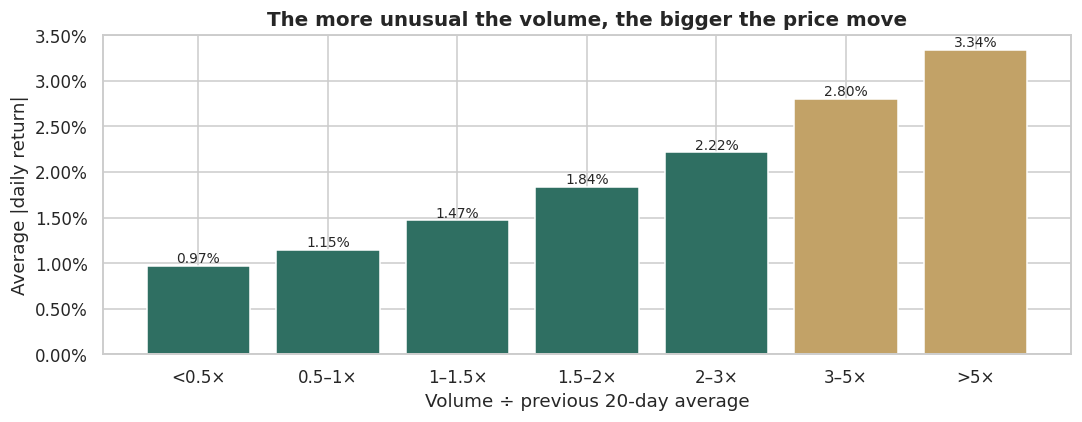

Spearman correlation between relative volume and the size of the move: 0.26


In [91]:
bins = [0, 0.5, 1, 1.5, 2, 3, 5, np.inf]
labels = ["<0.5×", "0.5–1×", "1–1.5×", "1.5–2×", "2–3×", "3–5×", ">5×"]
v = v.assign(bucket=pd.cut(v["Volume_Ratio"], bins, labels=labels))
by_bucket = v.groupby("bucket", observed=True)["Daily_Return"].apply(lambda x: x.abs().mean())
fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(by_bucket.index.astype(str), by_bucket.values, color=[EMERALD] * 5 + [SAND] * 2)
for i, val in enumerate(by_bucket.values):
    ax.text(i, val, f"{val:.2%}", ha="center", va="bottom", fontsize=9)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set(title="The more unusual the volume, the bigger the price move", xlabel="Volume ÷ previous 20-day average",
       ylabel="Average |daily return|")
plt.tight_layout(); plt.show()
from scipy.stats import spearmanr
rho = spearmanr(v["Volume_Ratio"], v["Daily_Return"].abs()).correlation
R["q2_rho"] = f"{rho:.2f}"
print(f"Spearman correlation between relative volume and the size of the move: {rho:.2f}")

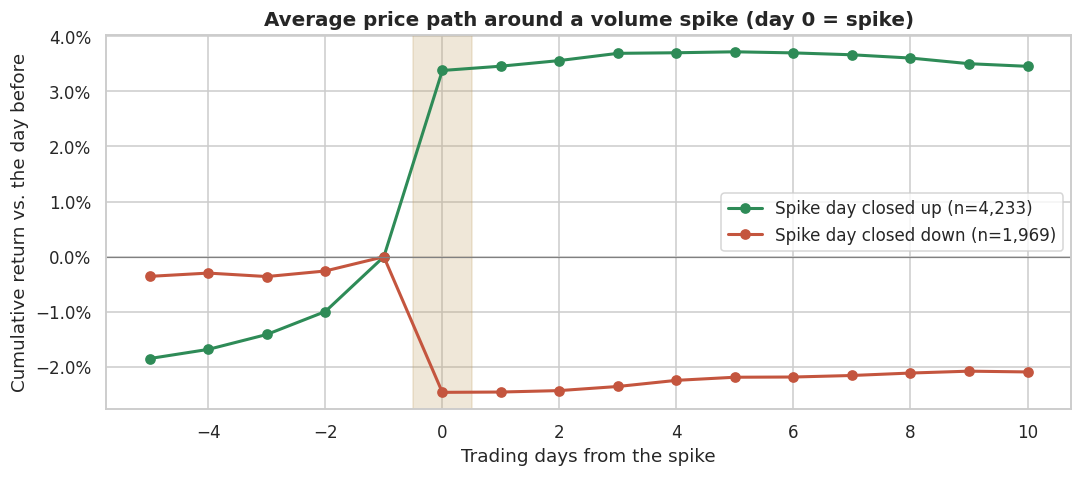

In [92]:
offsets = list(range(-5, 11))
gr = df_clean.groupby("Stock_Symbol")["Daily_Return"]
shifted = pd.concat({o: gr.shift(-o) for o in offsets}, axis=1)
spike_mask = (df_clean["Volume_Ratio"] >= 3) & df_clean["Daily_Return"].notna()
fig, ax = plt.subplots(figsize=(10, 4.5))
for name, mask, col in (("Spike day closed up", spike_mask & (df_clean["Daily_Return"] > 0), GREEN),
                        ("Spike day closed down", spike_mask & (df_clean["Daily_Return"] < 0), RED)):
    path = np.cumprod(1 + shifted[mask].mean().fillna(0).values)
    path = path / path[offsets.index(-1)] - 1
    ax.plot(offsets, path, marker="o", color=col, lw=2, label=f"{name} (n={mask.sum():,})")
    R["q2_after_up" if col == GREEN else "q2_after_down"] = f"{path[-1] - path[offsets.index(0)]:+.1%}"
ax.axvspan(-.5, .5, color=SAND, alpha=.25); ax.axhline(0, color="grey", lw=.8)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set(title="Average price path around a volume spike (day 0 = spike)", xlabel="Trading days from the spike",
       ylabel="Cumulative return vs. the day before")
ax.legend(); plt.tight_layout(); plt.show()

**Answer Q2:** Yes, volume spikes clearly come with bigger price moves, although they are not a reliable signal of direction.
Spikes are rare (6,383 days, 4.3% of all stock-days), but on those days the average move is 3.00%, about 2.3 × a normal day (1.28%). A spike day closes above its 20-day high 28% of the time versus 4% on normal days, and makes a move bigger than 3 % 39% of the time (normal: 9%).
Breakdowns are only slightly more frequent (8% vs 7%). The bar chart shows a steady staircase: the more
unusual the volume, the larger the move (Spearman ρ = 0.26). After the spike, the price does not continue or reverse
strongly afterwards (over the next 10 days the average stock moves only +0.1% after up-spikes and +0.4% after down-spikes), so the spike day itself carries most of the move.

### Q3 · How strongly are the top (blue-chip) stocks correlated with each other?
The 10 stocks with the highest total traded value are taken as the blue chips. Correlation is measured on
daily returns, not on prices, two stocks whose prices both trend upward would look correlated even if their daily moves
are unrelated (spurious correlation).

In [93]:
blue = (df_clean.groupby(["Stock_Symbol", "Company_Name", "Stock_Sector"])["Traded_Value"].sum()
        .nlargest(10).reset_index())
blue["Traded_Value"] = (blue["Traded_Value"] / 1e9).round(1)
blue.rename(columns={"Traded_Value": "Traded value (bn SAR)"})

,Stock_Symbol,Company_Name,Stock_Sector,Traded value (bn SAR)
0,1120,Al Rajhi Bank,Banks,335.0
1,2222,Saudi Aramco,Energy,299.1
2,1180,SNB,Banks,161.9
3,1150,Alinma Bank,Banks,153.8
4,7010,STC,Telecommunication Services,147.9
5,2010,SABIC,Materials,127.3
6,1211,Maaden,Materials,116.6
7,2082,ACWA Power,Utilities,95.2
8,2020,SABIC Agri-Nutrients,Materials,85.4
9,7203,Elm,Software & Services,80.9


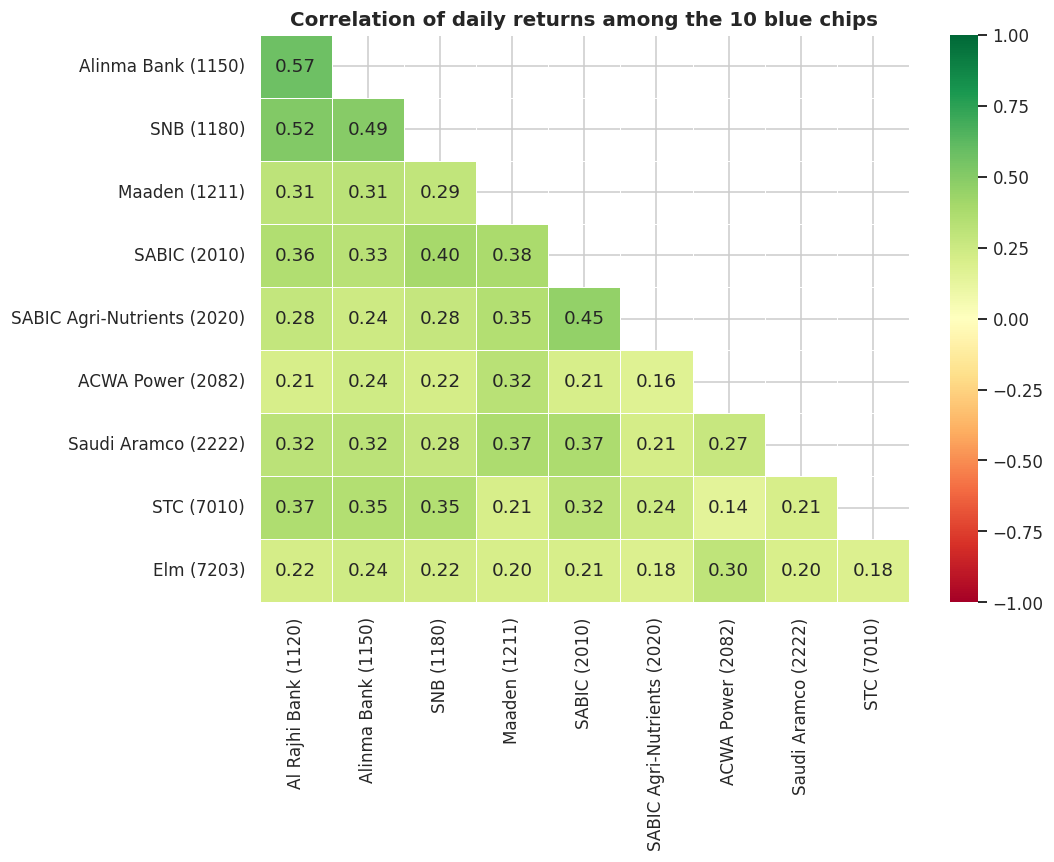

In [94]:
labels = {r.Stock_Symbol: f"{r.Company_Name} ({r.Stock_Symbol})" for r in blue.itertuples()}
sub = df_clean[df_clean["Stock_Symbol"].isin(labels)]
ret_corr = sub.pivot_table(index="Date", columns="Stock_Symbol", values="Daily_Return").corr().rename(index=labels, columns=labels)
price_corr = sub.pivot_table(index="Date", columns="Stock_Symbol", values="Close_Price").corr().rename(index=labels, columns=labels)
tri = ret_corr.iloc[1:, :-1]
mask = np.triu(np.ones(tri.shape, bool), 1)
plt.figure(figsize=(10, 8))
sns.heatmap(tri, mask=mask, annot=True, fmt=".2f", cmap="RdYlGn", vmin=-1, vmax=1, linewidths=.5)
plt.title("Correlation of daily returns among the 10 blue chips"); plt.xlabel(""); plt.ylabel(""); plt.tight_layout(); plt.show()

In [95]:
upper = np.triu(np.ones(ret_corr.shape, bool), 1)
pairs = ret_corr.where(upper).stack().dropna().sort_values(ascending=False)
price_pairs = price_corr.where(upper).stack().dropna()
R["q3_avg"], R["q3_price_avg"] = f"{pairs.mean():.2f}", f"{price_pairs.mean():.2f}"
(a1, b1), (a2, b2) = pairs.index[0], pairs.index[-1]
R["q3_top"], R["q3_top_v"] = f"{a1} & {b1}", f"{pairs.iloc[0]:.2f}"
R["q3_low"], R["q3_low_v"] = f"{a2} & {b2}", f"{pairs.iloc[-1]:.2f}"
R["q3_strong"] = int((pairs >= 0.5).sum())
print(f"Average return correlation: {pairs.mean():.2f} | average PRICE correlation: {price_pairs.mean():.2f}")
pd.concat({"Most correlated": pairs.head(5).round(2), "Least correlated": pairs.tail(5).round(2)}).to_frame("correlation")

Average return correlation: 0.29 | average PRICE correlation: 0.06


correlation
                 Stock_Symbol                Stock_Symbol                            
Most correlated  Al Rajhi Bank (1120)        Alinma Bank (1150)                  0.57
                                             SNB (1180)                          0.52
                 Alinma Bank (1150)          SNB (1180)                          0.49
                 SABIC (2010)                SABIC Agri-Nutrients (2020)         0.45
                 SNB (1180)                  SABIC (2010)                        0.40
Least correlated Saudi Aramco (2222)         Elm (7203)                          0.20
                 SABIC Agri-Nutrients (2020) Elm (7203)                          0.18
                 STC (7010)                  Elm (7203)                          0.18
                 SABIC Agri-Nutrients (2020) ACWA Power (2082)                   0.16
                 ACWA Power (2082)           STC (7010)                          0.14

/tmp/ipykernel_1880/2247203788.py:4: RuntimeWarning: Mean of empty slice
  avg_roll = roll.groupby(level=0).apply(lambda m: np.nanmean(m.values[tri]) if m.shape == (n, n) else np.nan).dropna()


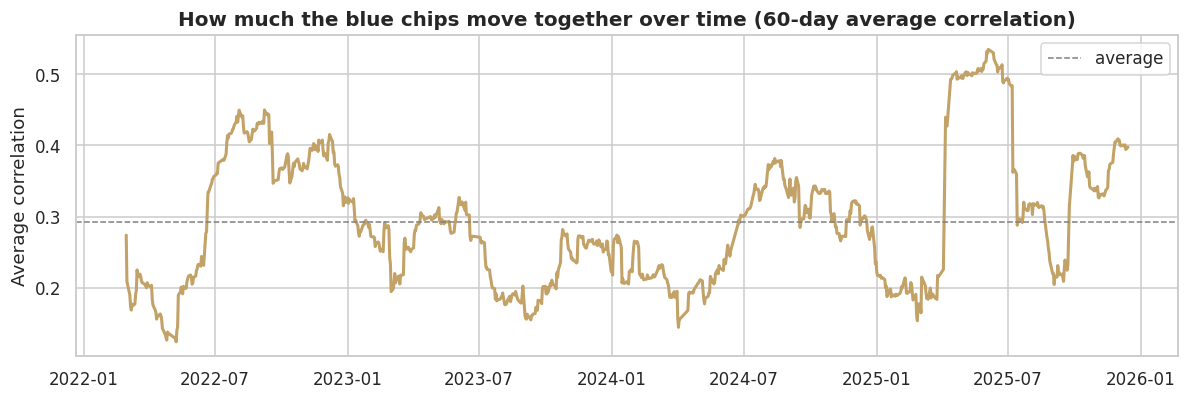

In [96]:
roll = (sub.pivot_table(index="Date", columns="Stock_Symbol", values="Daily_Return")
        .rolling(60, min_periods=40).corr())
n = len(labels); tri = np.triu(np.ones((n, n), bool), 1)
avg_roll = roll.groupby(level=0).apply(lambda m: np.nanmean(m.values[tri]) if m.shape == (n, n) else np.nan).dropna()
fig, ax = plt.subplots(figsize=(11, 3.8))
ax.plot(avg_roll.index, avg_roll.values, color=SAND, lw=2)
ax.axhline(avg_roll.mean(), color="grey", ls="--", lw=1, label="average")
ax.set(title="How much the blue chips move together over time (60-day average correlation)", ylabel="Average correlation")
ax.legend(); plt.tight_layout(); plt.show()
R["q3_peak"], R["q3_peak_v"] = avg_roll.idxmax().strftime("%B %Y"), f"{avg_roll.max():.2f}"

**Answer Q3:** the blue chips are moderately and positively correlated: the average correlation of their daily returns is 0.29, so they usually move in the same direction but far from in lock-step. The strongest links are inside the same sector: the three banks (Al Rajhi, Alinma and SNB) form the tightest cluster, with Al Rajhi Bank & Alinma Bank at 0.57. ACWA Power & STC are the most independent pair (0.14), so combining stocks from different sectors gives the most diversification. Only 2 of the 45 pairs reach 0.5 or more.

Correlation is not constant over time. It jumped sharply after the market-wide sell-off of 6 April 2025 (the average stock fell 7.6% that day) and stayed high until June, reaching 0.53. This shows that diversification helps least during stress, exactly when it is needed most. Measuring on returns was essential: the average price correlation is only 0.06, which would give a completely different and misleading picture.

### Q4 · Which stocks show the highest price volatility relative to their average price?
Two complementary measures (stocks with at least 60 trading days):
* **Coefficient of variation (CV)** = standard deviation of the price ÷ average price → how widely the price wandered over the
  whole period (captures big trends as well as noise).
* **Annualised volatility** = standard deviation of daily returns × √250 → how much the price shakes from day to day.

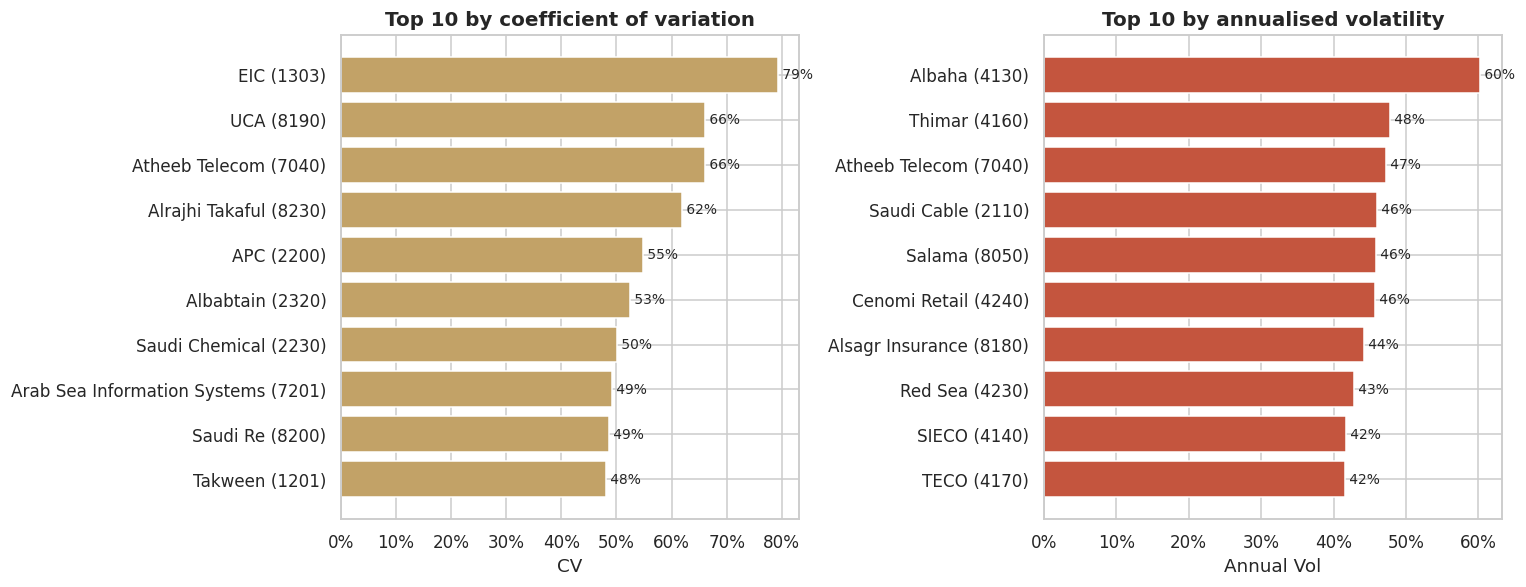

In [97]:
st = (df_clean.groupby(["Stock_Symbol", "Company_Name", "Stock_Sector"])
      .agg(mean_price=("Close_Price", "mean"), std_price=("Close_Price", "std"),
           daily_vol=("Daily_Return", "std"), days=("Date", "size")).reset_index())
st = st[st["days"] >= 60].copy()
st["CV"] = st["std_price"] / st["mean_price"]
st["Annual_Vol"] = st["daily_vol"] * np.sqrt(250)
st["Label"] = st["Company_Name"] + " (" + st["Stock_Symbol"].astype(str) + ")"

fig, ax = plt.subplots(1, 2, figsize=(14, 5.5))
for a, col, title in ((ax[0], "CV", "Top 10 by coefficient of variation"),
                      (ax[1], "Annual_Vol", "Top 10 by annualised volatility")):
    top = st.nlargest(10, col).iloc[::-1]
    a.barh(top["Label"], top[col], color=SAND if col == "CV" else RED)
    for i, val in enumerate(top[col]):
        a.text(val, i, f" {val:.0%}", va="center", fontsize=9)
    a.xaxis.set_major_formatter(mtick.PercentFormatter(1.0)); a.set(title=title, xlabel=col.replace("_", " "))
plt.tight_layout(); plt.show()

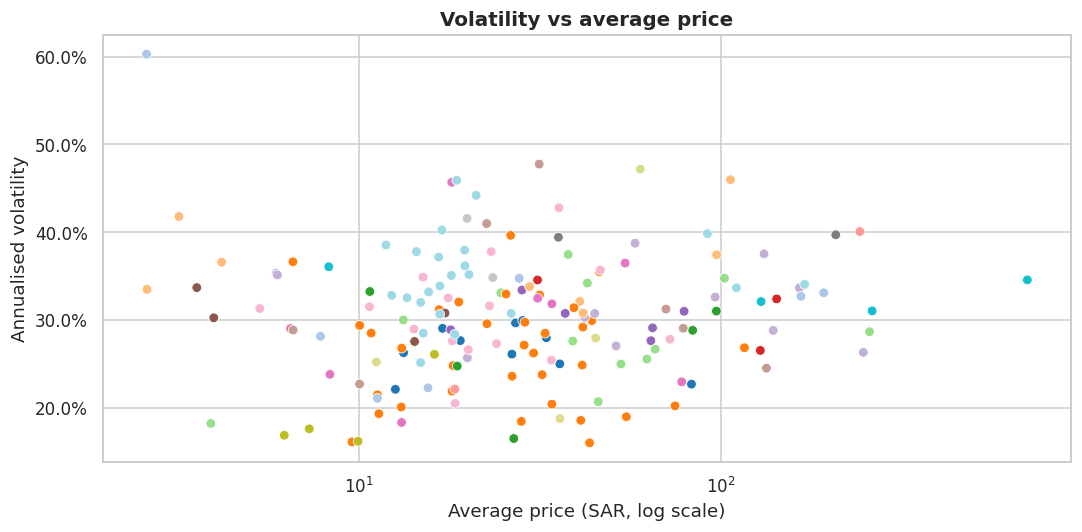

Median annualised volatility: 30% | price-vs-volatility Spearman: 0.08


,median annualised volatility
Stock_Sector,
REITs,17%
Telecommunication Services,27%
Materials,27%
Banks,27%
Food & Beverages,28%
Energy,29%
Consumer Staples Distribution & Retail,29%
Transportation,30%
Consumer Discretionary Distribution & Retail,30%


In [98]:
fig, ax = plt.subplots(figsize=(10, 5))
sns.scatterplot(data=st, x="mean_price", y="Annual_Vol", hue="Stock_Sector", s=40, ax=ax, legend=False, palette="tab20")
ax.set(xscale="log", title="Volatility vs average price", xlabel="Average price (SAR, log scale)", ylabel="Annualised volatility")
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0)); plt.tight_layout(); plt.show()
from scipy.stats import spearmanr
rho_pv = spearmanr(st["mean_price"], st["Annual_Vol"]).correlation
group_vol = st.groupby("Stock_Sector")["Annual_Vol"].median().sort_values()
top_cv, top_av, low_av = st.nlargest(1, "CV").iloc[0], st.nlargest(1, "Annual_Vol").iloc[0], st.nsmallest(1, "Annual_Vol").iloc[0]
R["q4_cv"], R["q4_cv_v"] = top_cv["Label"], f"{top_cv['CV']:.0%}"
R["q4_av"], R["q4_av_v"] = top_av["Label"], f"{top_av['Annual_Vol']:.0%}"
R["q4_low"], R["q4_low_v"] = low_av["Label"], f"{low_av['Annual_Vol']:.0%}"
R["q4_med"] = f"{st['Annual_Vol'].median():.0%}"
R["q4_overlap"] = len(set(st.nlargest(10, "CV")["Label"]) & set(st.nlargest(10, "Annual_Vol")["Label"]))
R["q4_rho"] = f"{rho_pv:.2f}"
R["q4_rho_txt"] = ("cheaper stocks tend to be more volatile" if rho_pv < -0.2 else
                   "pricier stocks tend to be more volatile" if rho_pv > 0.2 else
                   "the price level tells almost nothing about volatility — a cheap stock is not automatically a risky one")
R["q4_calm_grp"], R["q4_wild_grp"] = group_vol.index[0], group_vol.index[-1]
print(f"Median annualised volatility: {st['Annual_Vol'].median():.0%} | price-vs-volatility Spearman: {rho_pv:.2f}")
group_vol.map("{:.0%}".format).rename("median annualised volatility").to_frame()

**Answer Q4:** by coefficient of variation, the most volatile stock relative to its price is EIC (1303) (CV = 79%). Its price rose about 12× over the four years, which shows that a high CV mostly reflects a strong trend. UCA (8190), second by CV, shows the opposite: its price fell about 89%. By day-to-day volatility, Albaha (4130) is the jumpiest, at 60% a year against a market median of 30%. It is a penny stock (about 2.6 SAR), and cheap shares tend to move more in percentage terms.

The calmest stocks are tied at about 16%: Saudi Cement, Northern Cement, Taleem REIT and Saudi Aramco. So the largest company in the market is also one of the most stable.

The two rankings share only 1 of their top 10 (Atheeb Telecom), so trend risk and daily risk are different things, and investors should look at both.

Across all stocks, price level and volatility are almost unrelated (Spearman ρ = 0.08, not statistically significant), so a cheap stock is not automatically a risky one.

By industry group, REITs are the calmest (median 17%) and Media & Entertainment the most volatile (40%). These two groups contain only 4 and 2 stocks, so their results depend on very few companies.

## 6. Conclusions

### Main insights
| Question | Answer |
|---|---|
| **Q1** Sector performance | The average stock ended almost flat (+1.7%, with a −29% fall on the way), but groups diverged widely: **Telecommunication Services** +95%, **Media and Entertainment** −53%, and only 9 of 20 groups finished positive. 2023 was the strongest year, 2025 the weakest. |
| **Q2** Volume spikes | Spike days move ≈ 2.3× more than normal days (3.00% vs 1.28%) and close above the 20-day high 28% of the time (vs 4%). Breakdowns barely change (8% vs 7%), so spikes signal volatility, not direction. |
| **Q3** Blue-chip correlation | Moderate positive correlation (average 0.29). The banks form the tightest cluster (Al Rajhi & Alinma 0.57); ACWA Power & STC are the most independent (0.14). Correlation jumped after the market-wide sell-off of 6 April 2025, so diversification helps least in stress. |
| **Q4** Volatility vs price | Highest CV: EIC (1303), driven by a ≈12× price rise; highest daily volatility: Albaha (4130), a penny stock; calmest (≈16%): Saudi Cement, Northern Cement, Taleem REIT and Saudi Aramco. Price level does not predict volatility (ρ = 0.08). |


### What I learned
* Correlation should be measured on returns, not prices.
* Skewed financial data needs medians and log scales; averages alone are misleading.
* Turning an analysis into an interactive dashboard (Streamlit) makes the results easier to explore and explain.


### Limitations
* Prices come from Yahoo Finance , not Tadawul's official feed.
* Names and sectors attached from Yahoo Finance during preparation had to be checked and aligned with the official list of Tadawul companies.
* Short history for 2024–25 listings
* Equal weights, not the official TASI

### Recommendations
* **Investors:** diversify across industry groups, group returns differed by tens of percentage points over the period.
* **Traders:** treat a volume spike as a warning that a large move is under way, not as a buy or sell signal by itself.
* **Risk management:** combine CV and return volatility; do not rely on blue-chip diversification during market-wide stress.
* **Further work:** add market-cap weights to compare with TASI, include news and earnings dates to explain volume spikes, and build a simple predictive model for next-day volatility.